In [1]:
# = CLASSIFICACAO (Benign vs malignant)  

# Copie e cole no notebook do SageMaker Studio AI (Learner Lab)

import boto3
import json

#classificaçao
# Nome do endpoint
endpoint_name = "endpoint-jumpstart" #Digite o nome do seu endpoint


# Caminho da imagem no S3
bucket = "bucket-image-test-v2"      #Digite o nome do seu bucket
key = "dataset_lumbar/P8__slice001__P8L3.seg__150x150.jpg" #Digite o nome da imagem

# Clientes AWS
s3 = boto3.client("s3")
runtime = boto3.client("sagemaker-runtime")

# Baixar imagem do S3
obj = s3.get_object(Bucket=bucket, Key=key)
image_bytes = obj["Body"].read()

# Enviar para o endpoint
response = runtime.invoke_endpoint(
    EndpointName=endpoint_name,
    ContentType="application/x-image",
    Body=image_bytes
)

result = json.loads(response["Body"].read().decode())
print(result)

ValidationError: An error occurred (ValidationError) when calling the InvokeEndpoint operation: Endpoint endpoint-jumpstart of account 447339824885 not found.

In [5]:
import os

print("Diretório atual:", os.getcwd())
print("Home:", os.path.expanduser("~"))

Diretório atual: /home/ec2-user/SageMaker
Home: /home/ec2-user


In [6]:
import boto3

s3 = boto3.client("s3")

bucket = "bucket-image-test-v2"
key = "dataset_lumbar/Saída/jumpstart-dft-pt-ic-vgg16-20260903-183207/output/model.tar.gz"

local_artifact = "/home/ec2-user/SageMaker/model.tar.gz"

s3.download_file(
    bucket,
    key,
    local_artifact
)

print("Artefato baixado em:", local_artifact)

Artefato baixado em: /home/ec2-user/SageMaker/model.tar.gz


In [7]:
import tarfile
import os

extract_dir = "/home/ec2-user/SageMaker/vgg16_model"
os.makedirs(extract_dir, exist_ok=True)

with tarfile.open(local_artifact, "r:gz") as tar:
    tar.extractall(extract_dir)

print("Conteúdo extraído:")

for root, dirs, files in os.walk(extract_dir):
    for file in files:
        print(os.path.join(root, file))

Conteúdo extraído:
/home/ec2-user/SageMaker/vgg16_model/labels_info.json
/home/ec2-user/SageMaker/vgg16_model/model.pth
/home/ec2-user/SageMaker/vgg16_model/__models_info__.json
/home/ec2-user/SageMaker/vgg16_model/code/inference.py
/home/ec2-user/SageMaker/vgg16_model/code/__script_info__.json
/home/ec2-user/SageMaker/vgg16_model/code/__init__.py
/home/ec2-user/SageMaker/vgg16_model/code/version
/home/ec2-user/SageMaker/vgg16_model/code/constants/constants.py
/home/ec2-user/SageMaker/vgg16_model/code/constants/__init__.py


In [16]:
pip install --no-cache-dir torch torchvision --index-url https://download.pytorch.org/whl/cpu

Looking in indexes: https://download.pytorch.org/whl/cpu
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 196.2/196.2 MB 340.9 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 370.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 230.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 334.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 536.2/536.2 kB 140.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [torchvision] [torchvision]
Note: you may need to restart the kernel to use updated packages.


In [17]:
import torch
import torchvision

print(torch.__version__)
print(torchvision.__version__)
print("CUDA disponível:", torch.cuda.is_available())

2.14.0+cpu
0.29.0+cpu
CUDA disponível: False


In [18]:
import torch

weights_path = "/home/ec2-user/SageMaker/vgg16_model/model.pth"

checkpoint = torch.load(
    weights_path,
    map_location="cpu",
    weights_only=False
)

print("Tipo:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nChaves:")
    print(list(checkpoint.keys())[:30])

Tipo: <class 'torchvision.models.vgg.VGG'>


In [19]:
inference_path = "/home/ec2-user/SageMaker/vgg16_model/code/inference.py"

with open(inference_path, "r") as f:
    inference_code = f.read()

print(inference_code)

"""Generic SM entrypoint for all supported inference tasks.

Read metadata and dispatch to task-specifc pipelines
This code is based on https://github.com/aws/sagemaker-pytorch-inference-toolkit
https://github.com/aws/sagemaker-inference-toolkit
https://github.com/aws/sagemaker-inference-toolkit/blob/master/src/sagemaker_inference/transformer.py
"""

import json
import logging
import os
import re

import numpy as np
import torch
from constants import constants
from PIL import Image
from sagemaker_inference import content_types
from sagemaker_inference import encoder
from six import BytesIO


logging.basicConfig(format="%(asctime)s %(message)s", level=logging.INFO)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class PyTorchIC:
    """Model class that wraps around the Torch model."""

    def __init__(self, model, model_dir):
        """Image classification class that wraps around the Torch model.

        Stores the model inside class and read the labels from 

In [15]:
!df -h /home/ec2-user

Filesystem      Size  Used Avail Use% Mounted on
/dev/nvme0n1p1  105G   82G   24G  78% /


In [12]:
pip cache dir

/home/ec2-user/.cache/pip
Note: you may need to restart the kernel to use updated packages.


In [13]:
pip cache info

Package index page cache location (pip v23.3+): /home/ec2-user/.cache/pip/http-v2
Package index page cache location (older pips): /home/ec2-user/.cache/pip/http
Package index page cache size: 5951.8 MB
Number of HTTP files: 1806
Locally built wheels location: /home/ec2-user/.cache/pip/wheels
Locally built wheels size: 1390.4 MB
Number of locally built wheels: 8
Note: you may need to restart the kernel to use updated packages.


In [14]:
pip cache purge

Files removed: 1814 (7342.2 MB)
Directories removed: 2912
Note: you may need to restart the kernel to use updated packages.


In [20]:
import torch

device = torch.device("cpu")

model = checkpoint.to(device)
model.eval()

print("Modelo carregado.")

Modelo carregado.


In [21]:
import torch.nn as nn

for i, layer in enumerate(model.features):
    if isinstance(layer, nn.Conv2d):
        print(i, layer)

0 Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
2 Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
5 Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
7 Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
10 Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
12 Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
14 Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
17 Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
19 Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
21 Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
24 Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
26 Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
28 Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))


In [22]:
target_layer = model.features[28]

print(target_layer)

Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))


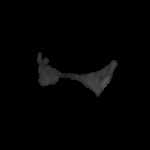

In [23]:
import boto3
from PIL import Image
from io import BytesIO
from torchvision import transforms
import torch

s3 = boto3.client("s3")

bucket = "bucket-image-test-v2"

key = "dataset_lumbar/P8__slice001__P8L3.seg__150x150.jpg"

obj = s3.get_object(
    Bucket=bucket,
    Key=key
)

image_bytes = obj["Body"].read()

image = Image.open(
    BytesIO(image_bytes)
).convert("RGB")

image

In [24]:
transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

input_tensor = (
    transform(image)
    .unsqueeze(0)
    .to(device)
)

In [25]:
with torch.no_grad():
    output = model(input_tensor)

probabilities = torch.softmax(output, dim=1)

predicted_class = probabilities.argmax(dim=1).item()

labels = ["BENIGN", "MALIGNANT"]

print("Classe prevista:", labels[predicted_class])
print("BENIGN:", probabilities[0, 0].item())
print("MALIGNANT:", probabilities[0, 1].item())

Classe prevista: BENIGN
BENIGN: 0.9999728202819824
MALIGNANT: 2.71698554570321e-05


In [26]:
class GradCAM:

    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        self.forward_hook = self.target_layer.register_forward_hook(
            self.save_activation
        )

        self.backward_hook = self.target_layer.register_full_backward_hook(
            self.save_gradient
        )

    def save_activation(self, module, inputs, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def __call__(self, x, class_idx=None):

        self.model.zero_grad()

        output = self.model(x)

        if class_idx is None:
            class_idx = output.argmax(dim=1).item()

        score = output[:, class_idx]

        score.backward()

        gradients = self.gradients
        activations = self.activations

        weights = gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        cam = (weights * activations).sum(dim=1)

        cam = torch.relu(cam)

        cam = (
            cam.squeeze()
            .detach()
            .cpu()
            .numpy()
        )

        cam = cam - cam.min()

        if cam.max() > 0:
            cam = cam / cam.max()

        return cam, class_idx

In [29]:
target_layer = model.features[28]

gradcam = GradCAM(
    model,
    target_layer
)

cam, class_idx = gradcam(
    input_tensor,
    class_idx=predicted_class
)

print("Classe analisada:", labels[class_idx])
print("Dimensão do Grad-CAM:", cam.shape)

Classe analisada: BENIGN
Dimensão do Grad-CAM: (14, 14)


In [28]:
import torch.nn as nn

for module in model.modules():
    if isinstance(module, nn.ReLU):
        module.inplace = False

print("ReLUs ajustadas.")

ReLUs ajustadas.


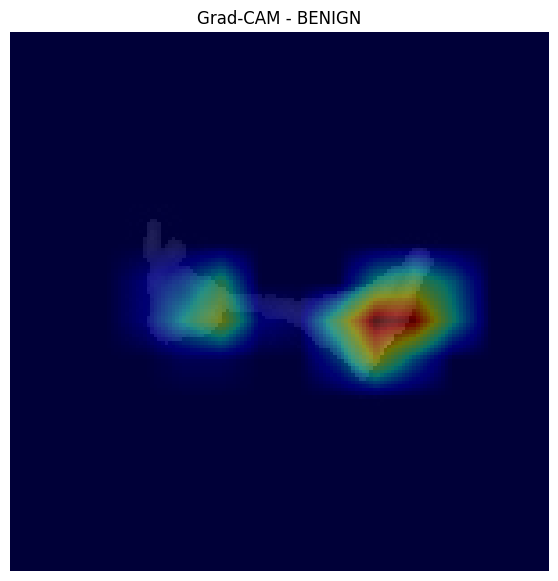

In [30]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Redimensionar o Grad-CAM para o tamanho da imagem original
cam_resized = Image.fromarray(
    (cam * 255).astype(np.uint8)
).resize(
    (image.width, image.height),
    resample=Image.BILINEAR
)

cam_resized = np.array(cam_resized) / 255.0

# Mostrar imagem + Grad-CAM
plt.figure(figsize=(7, 7))

plt.imshow(image)

plt.imshow(
    cam_resized,
    cmap="jet",
    alpha=0.45
)

plt.axis("off")
plt.title(f"Grad-CAM - {labels[class_idx]}")

plt.show()

In [31]:
original_path = "/home/ec2-user/SageMaker/imagem_original.png"

image.save(original_path)

print("Salva em:", original_path)

Salva em: /home/ec2-user/SageMaker/imagem_original.png


In [32]:
gradcam_path = "/home/ec2-user/SageMaker/gradcam_resultado.png"

plt.figure(figsize=(7, 7))
plt.imshow(image)
plt.imshow(
    cam_resized,
    cmap="jet",
    alpha=0.45
)

plt.axis("off")
plt.title(f"Grad-CAM - {labels[class_idx]}")

plt.savefig(
    gradcam_path,
    bbox_inches="tight",
    dpi=200
)

plt.close()

print("Salva em:", gradcam_path)

Salva em: /home/ec2-user/SageMaker/gradcam_resultado.png


In [33]:
import os

print(os.path.exists("/home/ec2-user/SageMaker/imagem_original.png"))
print(os.path.exists("/home/ec2-user/SageMaker/gradcam_resultado.png"))

True
True


In [34]:
import boto3

s3 = boto3.client("s3")

bucket = "bucket-image-test-v2"

s3.upload_file(
    "/home/ec2-user/SageMaker/imagem_original.png",
    bucket,
    "dataset_lumbar/gradcam/imagem_original.png"
)

s3.upload_file(
    "/home/ec2-user/SageMaker/gradcam_resultado.png",
    bucket,
    "dataset_lumbar/gradcam/gradcam_resultado.png"
)

print("Imagens enviadas para o S3.")

Imagens enviadas para o S3.
